# 환경 설정

## 한글화 코드

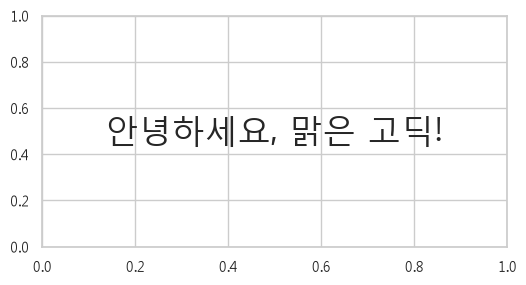

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

# seaborn 스타일을 먼저 적용
sns.set_theme(style="whitegrid")

# Windows 한글 글꼴 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 한글 표시 확인
plt.figure(figsize=(6, 3))
plt.text(
    0.5, 0.5,
    "안녕하세요, 맑은 고딕!",
    ha="center",
    va="center",
    size=24
)
plt.show()

## MySQL 연결

In [2]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine, URL, text

url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("MySQL 비밀번호: "),
    host="localhost",
    port=3306,
    database="final",
    query={"charset": "utf8mb4"},
)

engine = create_engine(url, pool_pre_ping=True)

# 연결 확인
with engine.connect() as conn:
    print(conn.execute(text("SELECT VERSION()")).scalar())

8.0.37


In [3]:
query = "SELECT * FROM accounts_user LIMIT 5"

with engine.connect() as conn:
    df = pd.read_sql_query(text(query), conn)

df.head()

,id,is_superuser,is_staff,gender,point,friend_id_list,is_push_on,created_at,block_user_id_list,hide_user_id_list,ban_status,report_count,alarm_count,pending_chat,pending_votes,group_id
0,831956,1,1,None,600,"[1292473, 913158, 1488461, 1064695, 1043565, 1...",0,2023-03-29 03:44:14.047130,[],[],N,0,0,0,0,NaN
1,831962,0,0,F,2248,"[833025, 832642, 982531, 879496, 838541, 83752...",1,2023-03-29 05:18:56.162368,[],[],N,253,40878,5499,110,12.0
2,832151,0,0,M,1519,"[838785, 982531, 882567, 879496, 838541, 83649...",0,2023-03-29 12:56:34.989468,[],[],N,0,37,0,47,1.0
3,832340,0,0,F,57,"[841345, 982531, 838785, 963714, 882567, 83252...",1,2023-03-29 12:56:35.020790,[],[],N,0,19,0,21,1.0
4,832520,0,0,M,1039,"[874050, 849763, 874212, 844297, 838541, 84004...",0,2023-03-29 12:56:35.049311,[],[],N,0,29,0,15,12.0


## DataFrame에 저장

In [4]:
import pandas as pd
from sqlalchemy import text

params = {
    "start_at": "2023-05-04 00:00:00",
    "end_at": "2024-05-06 00:00:00",
}

queries = {
    "polls_question": """
        SELECT
            id,
            TRIM(question_text) AS question_text,
            created_at
        FROM final.polls_question
    """,

    "polls_questionreport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            question_id,
            user_id
        FROM final.polls_questionreport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_usercandidate": """
        SELECT
            id,
            created_at,
            question_piece_id,
            user_id
        FROM final.polls_usercandidate
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionset": """
        SELECT
            id,
            question_piece_id_list,
            opening_time,
            status,
            user_id
        FROM final.polls_questionset
        WHERE opening_time >= created_at
          AND status = 'F'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionpiece": """
        SELECT
            id,
            is_voted,
            question_id,
            is_skipped
        FROM final.polls_questionpiece
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_userquestionrecord": """
        SELECT
            id,
            status,
            created_at,
            chosen_user_id,
            question_id,
            user_id,
            question_piece_id,
            has_read,
            answer_status,
            answer_updated_at,
            report_count,
            opened_times
        FROM final.accounts_userquestionrecord
        WHERE answer_status <> 'P'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_user": """
        SELECT
            id,
            is_superuser,
            is_staff,
            gender,
            friend_id_list,
            is_push_on,
            created_at,
            block_user_id_list,
            hide_user_id_list,
            ban_status,
            report_count,
            group_id
        FROM final.accounts_user
        WHERE is_superuser = 0
          AND is_staff = 0
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_timelinereport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            reported_user_id,
            user_id,
            user_question_record_id
        FROM final.accounts_timelinereport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_school": """
        SELECT
            id,
            student_count,
            school_type
        FROM final.accounts_school
    """,

    "accounts_group": """
        SELECT
            id,
            school_id
        FROM final.accounts_group
    """,

    "accounts_blockrecord": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            block_user_id,
            user_id
        FROM final.accounts_blockrecord
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,
}

# 테이블 이름을 키로 사용하는 DataFrame 모음
dfs = {}

with engine.connect() as conn:
    for table_name, query in queries.items():
        dfs[table_name] = pd.read_sql_query(
            text(query),
            conn,
            params=params,
        )

        df = dfs[table_name]
        print(f"{table_name}: {len(df):,}행 × {len(df.columns)}열")

# 개별 변수로도 사용
df_question = dfs["polls_question"]
df_questionreport = dfs["polls_questionreport"]
df_usercandidate = dfs["polls_usercandidate"]
df_questionset = dfs["polls_questionset"]
df_questionpiece = dfs["polls_questionpiece"]
df_userquestionrecord = dfs["accounts_userquestionrecord"]
df_user = dfs["accounts_user"]
df_timelinereport = dfs["accounts_timelinereport"]
df_school = dfs["accounts_school"]
df_group = dfs["accounts_group"]
df_blockrecord = dfs["accounts_blockrecord"]

polls_question: 5,025행 × 3열
polls_questionreport: 48,928행 × 5열
polls_usercandidate: 4,452,529행 × 4열
polls_questionset: 141,909행 × 5열
polls_questionpiece: 1,177,414행 × 4열
accounts_userquestionrecord: 1,128,249행 × 12열
accounts_user: 645,033행 × 12열
accounts_timelinereport: 208행 × 6열
accounts_school: 5,951행 × 3열
accounts_group: 84,515행 × 2열
accounts_blockrecord: 19,481행 × 5열


In [5]:
query_attendance = """
SELECT
    id,
    attendance_date_list,
    user_id
FROM final.accounts_attendance
"""

with engine.connect() as conn:
    df_attendance = pd.read_sql_query(text(query_attendance), conn)

dfs["accounts_attendance"] = df_attendance

print(f"accounts_attendance: {len(df_attendance):,}행 × {len(df_attendance.columns)}열")

df_attendance.head()

accounts_attendance: 349,637행 × 3열


,id,attendance_date_list,user_id
0,1,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1446852
1,2,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1359398
2,3,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1501542
3,4,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1507767
4,5,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1287453


# 전처리

## 중복값 확인

In [6]:
duplicate_results = []

for table_name, df in dfs.items():
    duplicate_results.append({
        "테이블": table_name,
        "전체 행 수": len(df),

        # 첫 행을 제외한 추가 중복 행 수
        "전체 컬럼 중복 행 수": int(df.duplicated().sum()),

        # 기본키 중복 및 누락
        "ID 중복 수": (
            int(df["id"].duplicated().sum())
            if "id" in df.columns else pd.NA
        ),
        "ID 결측 수": (
            int(df["id"].isna().sum())
            if "id" in df.columns else pd.NA
        ),
    })

df_duplicate_summary = pd.DataFrame(duplicate_results)

df_duplicate_summary

,테이블,전체 행 수,전체 컬럼 중복 행 수,ID 중복 수,ID 결측 수
0,polls_question,5025,0,0,0
1,polls_questionreport,48928,0,0,0
2,polls_usercandidate,4452529,0,0,0
3,polls_questionset,141909,0,0,0
4,polls_questionpiece,1177414,0,0,0
5,accounts_userquestionrecord,1128249,0,0,0
6,accounts_user,645033,0,0,0
7,accounts_timelinereport,208,0,0,0
8,accounts_school,5951,0,0,0
9,accounts_group,84515,0,0,0


# EDA

## 신고, 차단, 숨김 전체 비율

In [7]:
import json
import pandas as pd

user_base = df_user.copy()

# 일반 유저만 포함
user_base = user_base.loc[
    user_base["is_superuser"].eq(0)
    & user_base["is_staff"].eq(0)
].copy()

if user_base["id"].isna().any() or user_base["id"].duplicated().any():
    raise ValueError("유저 ID의 결측·중복을 먼저 확인해 주세요.")


def parse_id_list(value):
    if isinstance(value, str):
        parsed = json.loads(value)
    elif isinstance(value, list):
        parsed = value
    elif pd.isna(value):
        return None
    else:
        raise ValueError("숨김 목록 형식을 확인해 주세요.")

    if parsed is None:
        return None

    if not isinstance(parsed, list):
        raise ValueError("숨김 목록이 리스트 형식이 아닙니다.")

    return [int(user_id) for user_id in parsed]


# 차단당한 유저
blocked_ids = set(
    df_blockrecord["block_user_id"].dropna().astype("int64")
)

# 현재 user_base에 포함된 유저들이 숨김 처리한 대상
hide_lists = user_base["hide_user_id_list"].apply(parse_id_list)

hidden_ids = {
    user_id
    for ids in hide_lists
    if ids is not None
    for user_id in ids
}

df_user_negative_flags = user_base[["id", "report_count"]].copy()

df_user_negative_flags["신고당함"] = (
    df_user_negative_flags["report_count"].gt(0)
)
df_user_negative_flags["차단당함"] = (
    df_user_negative_flags["id"].isin(blocked_ids)
)
df_user_negative_flags["숨김당함"] = (
    df_user_negative_flags["id"].isin(hidden_ids)
)

print(f"분석 대상 일반 유저: {len(user_base):,}명")
print(f"숨김 목록 결측 유저: {hide_lists.isna().sum():,}명")

분석 대상 일반 유저: 645,033명
숨김 목록 결측 유저: 0명


In [8]:
total_users = len(df_user_negative_flags)

rows = []

for column in ["신고당함", "차단당함", "숨김당함"]:
    count = int(df_user_negative_flags[column].sum())

    rows.append({
        "구분": column,
        "고유 유저 수": count,
        "전체 대비 비율(%)": (
            count / total_users * 100
            if total_users else float("nan")
        ),
    })

df_negative_ratio = pd.DataFrame(rows)

df_negative_ratio.round(2)

,구분,고유 유저 수,전체 대비 비율(%)
0,신고당함,15339,2.38
1,차단당함,15645,2.43
2,숨김당함,276740,42.90


In [9]:
df_user_negative_flags["차단·숨김 구분"] = "둘 다 없음"

df_user_negative_flags.loc[
    df_user_negative_flags["차단당함"],
    "차단·숨김 구분",
] = "차단만"

df_user_negative_flags.loc[
    df_user_negative_flags["숨김당함"],
    "차단·숨김 구분",
] = "숨김만"

df_user_negative_flags.loc[
    df_user_negative_flags["차단당함"]
    & df_user_negative_flags["숨김당함"],
    "차단·숨김 구분",
] = "차단·숨김 모두"

df_block_hide_ratio = (
    df_user_negative_flags["차단·숨김 구분"]
    .value_counts()
    .reindex(
        ["차단만", "숨김만", "차단·숨김 모두", "둘 다 없음"],
        fill_value=0,
    )
    .rename_axis("구분")
    .reset_index(name="고유 유저 수")
)

df_block_hide_ratio["전체 대비 비율(%)"] = (
    df_block_hide_ratio["고유 유저 수"] / total_users * 100
    if total_users else float("nan")
)

df_block_hide_ratio.round(2)

,구분,고유 유저 수,전체 대비 비율(%)
0,차단만,5972,0.93
1,숨김만,267067,41.40
2,차단·숨김 모두,9673,1.50
3,둘 다 없음,362321,56.17


In [10]:
df_overall_ratio = pd.concat(
    [
        df_block_hide_ratio,
        df_negative_ratio.loc[
            df_negative_ratio["구분"].eq("신고당함")
        ].assign(구분="신고"),
    ],
    ignore_index=True,
)

df_overall_ratio.round(2)

,구분,고유 유저 수,전체 대비 비율(%)
0,차단만,5972,0.93
1,숨김만,267067,41.40
2,차단·숨김 모두,9673,1.50
3,둘 다 없음,362321,56.17
4,신고,15339,2.38


## 신고, 차단에 대한 사유 전체 비율

### 성별

#### 성별별 신고율이 높은 질문 Top 10

In [13]:
# '불쾌한 질문 내용' 사유만 추출
df_unpleasant_reports = (
    df_questionreport.loc[
        df_questionreport["reason"]
        .astype("string")
        .str.strip()
        .eq("불쾌한 질문 내용")
        .fillna(False)
    ]
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(
            columns={"id": "question_id"}
        ),
        on="question_id",
        how="left",
        validate="many_to_one",
    )
)

def unpleasant_top10(gender_code, label):
    return (
        df_unpleasant_reports.loc[
            df_unpleasant_reports["gender"].eq(gender_code)
        ]
        .groupby(["question_id", "question_text"], dropna=False)
        .size()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "question_id"],
            ascending=[False, True],
        )
        .head(10)
        .rename(columns={
            "question_id": f"{label} 질문 ID",
            "question_text": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )

df_gender_unpleasant_top10 = pd.concat(
    [
        unpleasant_top10("F", "여학생"),
        unpleasant_top10("M", "남학생"),
    ],
    axis=1,
)

df_gender_unpleasant_top10

,여학생 질문 ID,여학생 질문명,여학생 신고 수,남학생 질문 ID,남학생 질문명,남학생 신고 수
0,398,등빨이 가장 좋은 사람은?,193,410,발냄새가 호두과자 냄새일 것 같은 사람은?,108
1,111,마스크가 잘 어울리는 사람은?,179,111,마스크가 잘 어울리는 사람은?,30
2,410,발냄새가 호두과자 냄새일 것 같은 사람은?,173,477,항상 냄새를 맡으려고 하는 친구는?,29
3,424,어깨가 가장 넓은 사람은?,131,564,설레면 콧구멍이 커지는 친구는?,28
4,305,먹방을 가장 잘할 것 같은 사람은?,98,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,24
5,564,설레면 콧구멍이 커지는 친구는?,72,144,발냄새가 가장 향긋할 것 같은 사람은?,24
6,538,이모티콘만 보고 알아서 상상해서 골라봐,64,305,먹방을 가장 잘할 것 같은 사람은?,23
7,362,땀냄새가 가장 좋을 것 같은 사람은?,50,108,가장 매력적인 사람은?,22
8,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,49,416,발가락에서 페브리즈향이 날 것 같은 사람은?,22
9,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,46,391,플러팅을 제일 잘하는 사람은?,20


#### 신고 차단 성별 비율

#### 성별 질문 신고 사유 유저 차단 사유 Top 10

### 학급

#### 중학교, 고등학교 신고율이 높은 질문 Top 10

#### 신고·차단 학급별 비율

#### 학급별 질문 신고 사유·유저 차단 사유 Top 10

### 차단 & 숨김 같이 활용될 시 다르게 보이는 패턴

#### 질문 수신량

#### 투표 받은 횟수

#### 출석일 수 (보조지표)

## 신고 당한 이후의 후속 조치 양상

#### 신고 이후 기간 질문이 다시 노출되는지

#### 새로운 질문이 추가 되었는지